# Perceiving China: Cross-National Attitudes Towards Information Freedom and Censorship

## 1. Literature Review

### 1.2 Digital Freedom and Perceptions of China

The *People’s Republic of China* occupies a prominent position in global debates on information freedom, frequently portrayed as the best example of a digital authoritarian state in many liberal democracies [1]. Despite the internet in China having over 1.12 billion users and a penetration rate of around 79.7% [13], China is consistently ranked among the most repressive countries for information freedom, receiving the lowest score for political rights and civil liberties from Freedom House [14] and placing 178th out of 180 countries in the Reporters Without Borders World Press Freedom Index in 2025 [15]. As emphasised in much Western media, the Chinese Communist Party retains extensive control over digital infrastructure [16, 17], online speech [18], and information flows [19] through content moderation and internet censorship mechanisms such as China’s “Great Firewall” [20, 21, 22]. Simultaneously, amidst intensifying competition with the United States, China’s pioneering advances in technology place it at the centre of global innovation [23]. Furthermore, China is an economic superpower, the world’s largest trading nation and the second-largest economy by nominal GDP [24]. This colossal weight often creates ambivalent relationships with many nations, who publicly condemn China’s digital policies while remaining deeply entwined with Chinese trade and investment. For example, despite maintaining robust trading ties, the United Kingdom and the United States consider China to be one of their most pressing security and economic threats [25, 26].

### 1.1 Theorising Cross-National Perceptions: From Social Psychology to Critical Theory

Cross-national survey research has long shown that people in different countries place varying degrees of importance on freedom and self-expression, suggesting that a country’s value profile may also shape how its own citizens evaluate foreign states, especially with regards to information control [2]. Social identity theory suggests that individuals derive part of their own self-concept from the groups they belong to, defining these ‘in-groups’ in contrast to relevant ‘out-groups’ [3]. Political scientists have extended this logic to the analysis of states, emphasising how nations construct an “Other” against which to articulate their own core values and anxieties [4]. Critical and reflexive approaches, often associated with the “self-reflexive turn” in anthropology [5, 6], brought questions of positionality, assumptions, and complicity in power to the forefront of social science research, prompting scholars to consider how narratives about others may reflect their own fears, interests, and contradictions [7]. Edward Said’s 1978 publication of Orientalism famously epitomised this shift by theorising how a Western imaginary of “the East” legitimises hierarchies between Self and Other [8]. Subsequent work has traced how such dynamics are reproduced in digital contexts, including forms of “techno-orientalism” in contemporary representations of Asian societies [9, 10, 11, 12]. These perspectives suggest that perceptions of China can be read not only as judgements about an external actor, but also as reflections of the societies doing the observing.

China’s global image is complex and contested [29] and public attitudes towards China are far from uniform across world regions. National perceptions of China are not simply neutral, but also mirror domestic debates about freedom, security, and technology governance. Much existing academic commentary foregrounds perspectives from Euro-American liberal democracies, while the views of populations in the global majority, referring to populations across, Africa, Latin America and parts of Asia and the Middle East remain comparatively underexamined [27, 28]. Whilst much political rhetoric, especially from the Global North, focuses on contrasting democratic values with authoritarian regimes, both China and the United States exhibit remarkable convergences with regards to regulating the internet, deploying new technologies, and confronting societal tensions around privacy, surveillance, content moderation and information control [30]. Whilst associations made about China within liberal democratic discourse may be true, these opinions are ultimately subjective and shaped by a citizen's own value judgements. The gaze through which such opinions are formed deserves closer scrutiny. This relationship raises questions about how governmental depictions of their own political virtues, and of distant states, shape citizens’ attitudes. 

- please reframe this as value placed on freedom in different countries
- cut the 'global majority' leftie rhetoric that has no backing. This will also help you cut words
- frame it as 'do geographic patterns emerge'? Don't over politicise unnecessarily
- emphasise 'geographic patterns'
- you must be nuanced, this can still be done through the authors you have cited. Acknowledge that some nations may have certain value judgements and biases
- your point needs to be trimmed down essentially
- make it empirical vibes - you can have some edward said commentary, but you want to focus on the fact that certain global regions have differing values when it comes to freedom from censorship
- Frame it as 'do countries cluster into distinct geographic regions' 'are there larger geographic patterns'? This is a more apolitical take..

## Methodology

### 2.1 Research Question and Hypothesis

How do cross-national perceptions of China correlate with attitudes towards censorship, and what patterns emerge across nations? It is hypothesised that stronger support for internet, speech and press freedom will be associated with more negative perceptions of China. Furthermore, this relationship will likely be stronger for Western liberal democracies, where favourability for China is likely to be lower. 

- "are there larger geographic patterns between regions"?

### 2.2 Data 

This analysis uses the Pew Spring Global Attitudes 2025 Survey, which collected data from a sample of n = 41,503 participants across 35 countries. The population of interest (Ω) consists of all participants from these 35 countries and the dataset used contains 654 variables. This study focuses on variables measuring favourability towards China, measured on a 4-point ordinal scale: "very favourable" (1), "somewhat favourable" (2), "somewhat unfavourable" (3), and "very unfavourable" (4). It also examines the importance nations place on freedom from censorship: using the sub-variables internet freedom, press freedom, and free speech. These variables were measured alongside one another, given their grouping under 'censorship' within the Pew survey. These are similarly measured using a 4-point ordinal scale, where respondents indicated whether each freedom was "very important" (1), "somewhat important" (2), "not too important" (3), or "not important at all" (4). Numeric labels (1–4) encode these scales, with lower values indicating more positive attitudes. Variables vary in their total number of valid responses. Non-response codes 8 ("don't know") and 9 ("refused") are also present in the dataset, but are excluded during analysis and considered non-valid. Freedom variables have between 1,951 – 2,204 missing or non-valid responses (4.7% – 5.3% of n), which are dropped from the analysis. Country-level statistics are calculated as weighted proportions following Pew's methodological guidance to ensure balanced representativeness of demographics during comparisons. Where the term "Global Majority" is referenced, the classification system used draws on Campbell-Stephens (2020). Tests ran on data are non-parametric and intentionally chosen for their appropriateness for working with ordinal data.

In [2]:
import plotly as pl
import matplotlib.pyplot as plt
import seaborn as s
import matplotlib as mp
import numpy as np
import pandas as pd
import os
import pathlib
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.colors as mcolors

In [3]:
pew = pd.read_csv("pew_dataset.csv", dtype=str) 

In [4]:
# convert relevant columns to numeric

pew['weight'] = pd.to_numeric(pew['weight'], errors='coerce')
pew['age'] = pd.to_numeric(pew['age'], errors='coerce')  
pew['id'] = pd.to_numeric(pew['id'], errors='coerce')  
pew['country'] = pd.to_numeric(pew['country'], errors='coerce') 

# create a python dictionary, generating an additional 'country' column from country-codes for easier readability

country_code_map = {
    2: "Canada",
    3: "France",
    4: "Germany",
    5: "Greece",
    6: "Hungary",
    7: "Italy",
    8: "Netherlands",
    9: "Poland",
    10: "Spain",
    11: "Sweden",
    12: "UK",
    13: "Australia",
    14: "Bangladesh",
    15: "India",
    16: "Indonesia",
    17: "Japan",
    18: "Malaysia",
    19: "Philippines",
    20: "Singapore",
    21: "South Korea",
    22: "Sri Lanka",
    23: "Thailand",
    24: "Israel",
    25: "Tunisia",
    26: "Turkey",
    27: "Ghana",
    28: "Kenya",
    29: "Nigeria",
    30: "South Africa",
    31: "Argentina",
    32: "Brazil",
    33: "Chile",
    34: "Colombia",
    35: "Mexico",
    36: "Peru"
}

pew['country_name'] = pew['country'].map(country_code_map)

## 3. Analysis

### 3.1 China favourability and freedom values: an inverse relationship

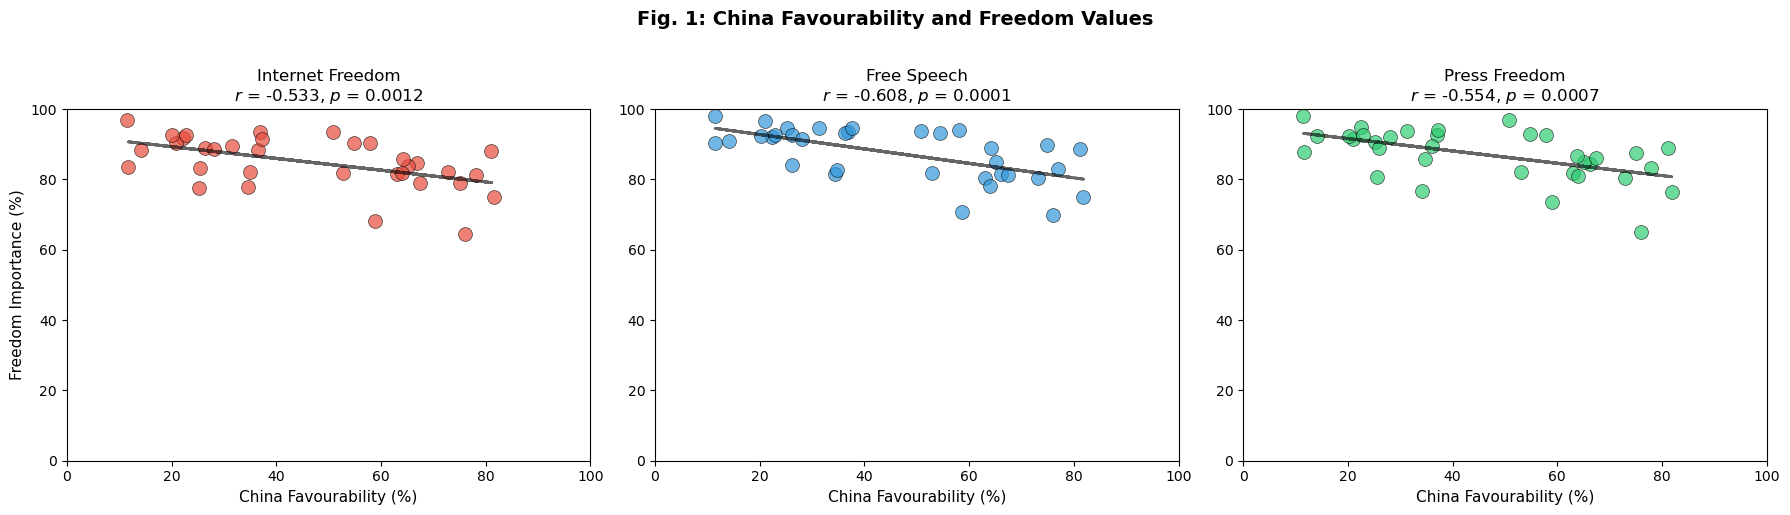

In [5]:
# Clean Combined Visualization: China Favorability vs All Three Freedom Variables
# Using subplots for clarity

# Reuse calculation function from before or recalculate
def calc_china_freedom_correlation(freedom_var):
    valid_data = pew[
        pew['fav_china'].isin(['1', '2', '3', '4']) & 
        pew[freedom_var].isin(['1', '2', '3', '4'])
    ].copy()
    valid_data['weight'] = pd.to_numeric(valid_data['weight'], errors='coerce')
    valid_data = valid_data.dropna(subset=['weight', 'country_name', 'fav_china', freedom_var])
    
    country_stats = {}
    for country in sorted(valid_data['country_name'].unique()):
        country_data = valid_data[valid_data['country_name'] == country]
        total_weight = country_data['weight'].sum()
        
        fav_china_favorable = country_data[country_data['fav_china'].isin(['1', '2'])]['weight'].sum()
        fav_china_favorable_pct = (fav_china_favorable / total_weight) * 100
        
        freedom_important = country_data[country_data[freedom_var].isin(['1', '2'])]['weight'].sum()
        freedom_important_pct = (freedom_important / total_weight) * 100
        
        country_stats[country] = {
            'fav_china_favorable_pct': fav_china_favorable_pct,
            'freedom_important_pct': freedom_important_pct
        }
    
    return pd.DataFrame(country_stats).T

plot_df_internet = calc_china_freedom_correlation('internet_freedom')
plot_df_speech = calc_china_freedom_correlation('free_speech')
plot_df_press = calc_china_freedom_correlation('press_freedom')

# Create figure with 3 subplots
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

from scipy import stats
from scipy.stats import spearmanr

# Define colors for each
colors = ['#e74c3c', '#3498db', '#2ecc71']
datasets = [
    (plot_df_internet, 'Internet Freedom', 'internet_freedom'),
    (plot_df_speech, 'Free Speech', 'free_speech'),
    (plot_df_press, 'Press Freedom', 'press_freedom')
]

for idx, (plot_df, title, var_name) in enumerate(datasets):
    ax = axes[idx]
    
    # Scatter plot
    ax.scatter(plot_df['fav_china_favorable_pct'], 
               plot_df['freedom_important_pct'], 
               s=100, alpha=0.7, color=colors[idx], edgecolors='black', linewidth=0.5)
    
    # Trend line
    z = np.polyfit(plot_df['fav_china_favorable_pct'], 
                   plot_df['freedom_important_pct'], 1)
    p = np.poly1d(z)
    ax.plot(plot_df['fav_china_favorable_pct'], 
            p(plot_df['fav_china_favorable_pct']), 
            color='black', linestyle='--', alpha=0.6, linewidth=2)
    
    # Calculate correlation
    corr, p_val = spearmanr(plot_df['fav_china_favorable_pct'], 
                            plot_df['freedom_important_pct'])
    
    # Customize
    ax.set_xlabel('China Favourability (%)', fontsize=11)
    if idx == 0:
        ax.set_ylabel('Freedom Importance (%)', fontsize=11)
    ax.set_title(f'{title}\n$r$ = {corr:.3f}, $p$ = {p_val:.4f}', 
                 fontsize=12)
    ax.grid(False)
    ax.set_xlim(0, 100)
    ax.set_ylim(0, 100)

plt.suptitle('Fig. 1: China Favourability and Freedom Values', 
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

Correlations between importance of freedom from state censorship and favourability towards China were analysed. For each country $c$, ordinal responses were converted into weighted proportions $p_c$ representing the percentage of participants rating each freedom as "very" or "somewhat" important (values 1 or 2). Spearman's rank correlation coefficient $r$ was calculated between $p_c$ values, testing the null hypothesis $\mathrm{H}_0: ρ = 0$. P-values $p$ represent the probability that a correlation of magnitude ≥ $|r|$ would occur by chance if no true relationship existed between variables. For internet freedom, $r = -0.533$, $p = 0.0012$; for free speech, $r = -0.60$, $p = 0.0001$; and for press freedom, $r = -0.554$, $p = 0.0007$. Strong negative correlations were observed, indicating an inverse relationship: countries with higher favorability toward China tend to place lower importance on internet, speech, and press freedoms, consistent with the hypothesis. P-values ranging from 0.0001 - 0.0012 indicates that observed correlations would occur by chance ≤ 0.12% of the time if no true relationship existed, providing strong evidence against $\mathrm{H}_0$.

### 3.2 Non-Western nations perceive China with greater favourability

/Users/teoboy/anaconda3/lib/python3.11/site-packages/cartopy/mpl/feature_artist.py:143: UserWarning: facecolor will have no effect as it has been defined as "never".
  warnings.warn('facecolor will have no effect as it has been '


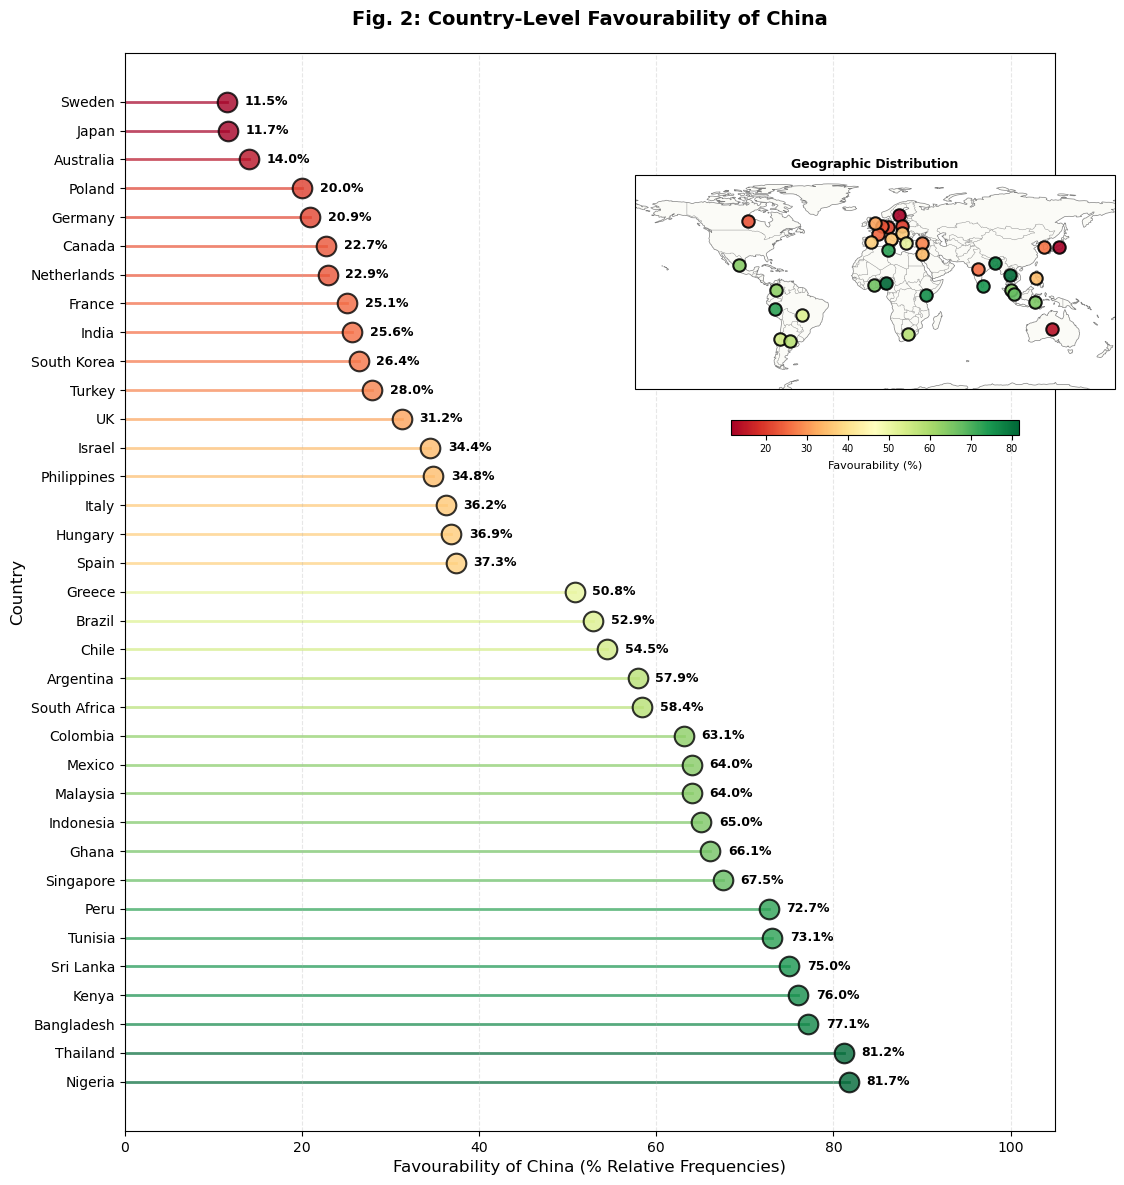

In [168]:

# Filter to valid responses
valid_data = pew[pew['fav_china'].isin(['1', '2', '3', '4'])].copy()
valid_data['weight'] = pd.to_numeric(valid_data['weight'], errors='coerce')
valid_data = valid_data.dropna(subset=['weight', 'country_name', 'fav_china'])

# Calculate weighted proportions for each country
country_stats = {}
for country in sorted(valid_data['country_name'].unique()):
    country_data = valid_data[valid_data['country_name'] == country]
    total_weight = country_data['weight'].sum()
    
    fav_china_favorable = country_data[country_data['fav_china'].isin(['1', '2'])]['weight'].sum()
    fav_china_favorable_pct = (fav_china_favorable / total_weight) * 100
    
    country_stats[country] = {
        'fav_china_favorable_pct': fav_china_favorable_pct
    }

plot_df = pd.DataFrame(country_stats).T

# Sort by China favorability for better visualization
plot_df = plot_df.sort_values('fav_china_favorable_pct', ascending=True)

# Create colormap for favorability gradient (low to high)
# Using RdYlGn: Red (low favorability) -> Yellow -> Green (high favorability)
cmap = plt.cm.RdYlGn  # Red to Green
norm = mcolors.Normalize(vmin=plot_df['fav_china_favorable_pct'].min(), 
                        vmax=plot_df['fav_china_favorable_pct'].max())

# Create lollipop chart with favorability gradient coloring
fig, ax = plt.subplots(figsize=(12, max(10, len(plot_df) * 0.4)))

y_pos = np.arange(len(plot_df))

# Plot lollipop with favorability gradient colors
for i, country in enumerate(plot_df.index):
    china_val = plot_df.loc[country, 'fav_china_favorable_pct']
    color = cmap(norm(china_val))  # Get color from gradient based on favorability
    
    # Draw line
    ax.plot([0, china_val], [i, i], color=color, linewidth=2, alpha=0.7, zorder=1)
    
    # Draw dot with gradient color
    ax.scatter(china_val, i, s=200, color=color, alpha=0.8, edgecolors='black', linewidth=1.5, zorder=3)
    
    # Add percentage text to the right of the dot
    ax.text(china_val + 2, i, f'{china_val:.1f}%', 
            va='center', fontsize=9, fontweight='bold', zorder=4)

# Create mini world map inset with favorability gradient dots
ax_map = fig.add_axes([0.55, 0.55, 0.40, 0.45], projection=ccrs.PlateCarree())

# Add base geographic features
ax_map.add_feature(cfeature.COASTLINE, linewidth=0.5, color='gray')
ax_map.add_feature(cfeature.BORDERS, linewidth=0.3, color='gray')
ax_map.add_feature(cfeature.LAND, alpha=0.2)

# Country coordinates for map (approximate centroids)
country_coords = {
    'UK': (0, 54), 'France': (2, 46), 'Germany': (10, 51), 'Italy': (12, 42),
    'Spain': (-3, 40), 'Poland': (20, 52), 'Netherlands': (5, 52), 'Sweden': (18, 60),
    'Greece': (23, 39), 'Hungary': (20, 47),
    'Canada': (-95, 56), 'United States': (-95, 38),
    'Japan': (138, 36), 'South Korea': (127, 36), 'India': (77, 20), 'Indonesia': (120, -5),
    'Malaysia': (102, 4), 'Philippines': (121, 13), 'Singapore': (104, 1), 'Thailand': (101, 15),
    'Bangladesh': (90, 24), 'Sri Lanka': (81, 7),
    'Israel': (35, 31), 'Tunisia': (10, 34), 'Turkey': (35, 39),
    'South Africa': (25, -29), 'Ghana': (-1, 8), 'Kenya': (38, 0), 'Nigeria': (8, 9),
    'Brazil': (-55, -15), 'Argentina': (-64, -34), 'Chile': (-71, -33), 'Colombia': (-74, 4),
    'Peru': (-75, -10), 'Mexico': (-102, 23),
    'Australia': (133, -25)
}

# Plot countries as dots with favorability gradient colors
for country in plot_df.index:
    if country in country_coords:
        lon, lat = country_coords[country]
        favorability = plot_df.loc[country, 'fav_china_favorable_pct']
        color = cmap(norm(favorability))  # Get color from gradient
        
        ax_map.scatter(lon, lat, s=80, c=[favorability], cmap=cmap, 
                      vmin=norm.vmin, vmax=norm.vmax, alpha=0.9, 
                      edgecolors='black', linewidth=1.5, zorder=5, 
                      transform=ccrs.PlateCarree())

# Add colorbar for favorability gradient
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax_map, orientation='horizontal', 
                   pad=0.05, shrink=0.6, aspect=20)
cbar.set_label('Favourability (%)', fontsize=8, labelpad=5)
cbar.ax.tick_params(labelsize=7)

# Set map bounds
ax_map.set_global()
ax_map.set_extent([-180, 180, -70, 90], crs=ccrs.PlateCarree())
ax_map.set_title('Geographic Distribution', fontsize=9, fontweight='bold', pad=5)

# Main plot settings
ax.set_yticks(y_pos)
ax.set_yticklabels(plot_df.index, fontsize=10)
ax.set_xlabel('Favourability of China (% Relative Frequencies)', fontsize=12)
ax.set_ylabel('Country', fontsize=12)
ax.set_title('Fig. 2: Country-Level Favourability of China',
             fontsize=14, fontweight='bold', pad=20)
ax.set_xlim(0, 105)  # Extended slightly to accommodate percentage text
ax.set_xticks(np.arange(0, 101, 20))
ax.grid(True, alpha=0.3, axis='x', linestyle='--')
ax.invert_yaxis()  # Top to bottom

plt.show()

A second test measured general baseline favourability toward China across all 35 countries. Upon excluding 4,232 non-valid or missing responses (10.2% of n = 41,503), the final sample included 37,271 valid responses. Expressed as relative frequencies for each country $c$, favourability was similarly operationalised as the weighted proportion $p_c$ of participants reporting "very favourable" (1) or "somewhat favorable" (2). Fig. 2 demonstrated that baseline China favourability varied significantly across nations, ranging from 11.5% to 82.2%, with a median of 50.8%. Sweden (11.5%), Japan (11.7%) and Australia (14.0%) showed the lowest favourability, while Nigeria (81.7%), Thailand (81.2%) and Bangladesh (77.1%) exhibited the highest. Countries typically associated with the Global Majority demonstrated systematically higher favorability toward China, with all countries ≥ 52.9% being Global Majority nations with the exception of Tunisia. Western nations clustered in the first two quartiles, with most in Q1 (Q1 median = 26%). India (25.6%) and the Philippines (34.8%) were the only Global Majority countries scoring below the overall median (< 50.8%). 

### 3.3 The US and EU are favoured to a greater extent than China

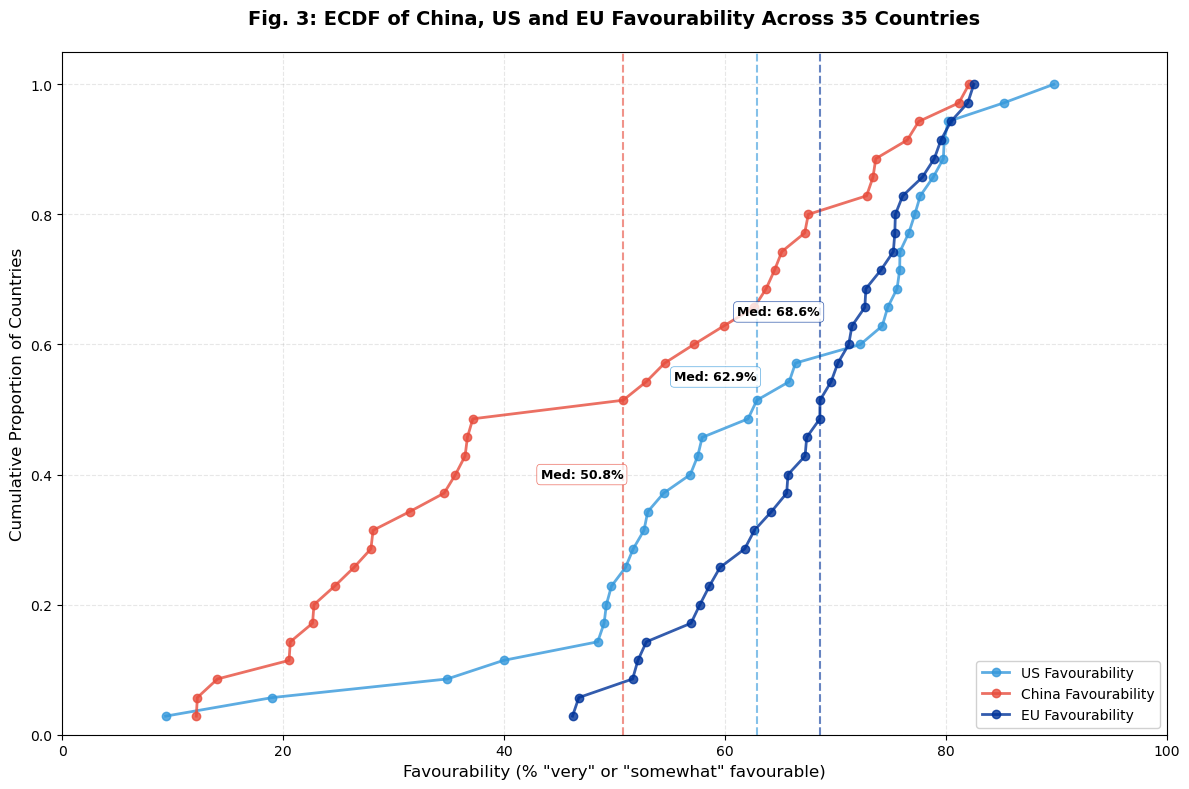

In [153]:
# Filter to valid responses for all three variables
valid_data = pew[
    pew['fav_us'].isin(['1', '2', '3', '4']) & 
    pew['fav_china'].isin(['1', '2', '3', '4']) &
    pew['fav_eu'].isin(['1', '2', '3', '4'])
].copy()
valid_data['weight'] = pd.to_numeric(valid_data['weight'], errors='coerce')
valid_data = valid_data.dropna(subset=['weight', 'country_name', 'fav_us', 'fav_china', 'fav_eu'])

country_stats = {}
for country in sorted(valid_data['country_name'].unique()):
    country_data = valid_data[valid_data['country_name'] == country]
    total_weight = country_data['weight'].sum()
    
    fav_us_favorable = country_data[country_data['fav_us'].isin(['1', '2'])]['weight'].sum()
    fav_us_favorable_pct = (fav_us_favorable / total_weight) * 100
    
    fav_china_favorable = country_data[country_data['fav_china'].isin(['1', '2'])]['weight'].sum()
    fav_china_favorable_pct = (fav_china_favorable / total_weight) * 100
    
    fav_eu_favorable = country_data[country_data['fav_eu'].isin(['1', '2'])]['weight'].sum()
    fav_eu_favorable_pct = (fav_eu_favorable / total_weight) * 100
    
    country_stats[country] = {
        'fav_us_favorable_pct': fav_us_favorable_pct,
        'fav_china_favorable_pct': fav_china_favorable_pct,
        'fav_eu_favorable_pct': fav_eu_favorable_pct
    }
plot_df = pd.DataFrame(country_stats).T

# Create ECDF function
def ecdf(data):
    """Compute ECDF for a one-dimensional array of measurements."""
    n = len(data)
    x = np.sort(data)
    y = np.arange(1, n+1) / n
    return x, y

# Compute ECDFs for all three variables
x_us, y_us = ecdf(plot_df['fav_us_favorable_pct'])
x_china, y_china = ecdf(plot_df['fav_china_favorable_pct'])
x_eu, y_eu = ecdf(plot_df['fav_eu_favorable_pct'])

# Create ECDF plot
fig, ax = plt.subplots(figsize=(12, 8))

# Plot ECDFs
ax.plot(x_us, y_us, marker='o', linestyle='-', linewidth=2, markersize=6,
        label='US Favourability', color='#3498db', alpha=0.8)
ax.plot(x_china, y_china, marker='o', linestyle='-', linewidth=2, markersize=6,
        label='China Favourability', color='#e74c3c', alpha=0.8)
ax.plot(x_eu, y_eu, marker='o', linestyle='-', linewidth=2, markersize=6,
        label='EU Favourability', color='#003399', alpha=0.8)

# Add median lines
# Add median lines (without labels in legend)
median_us = plot_df['fav_us_favorable_pct'].median()
median_china = plot_df['fav_china_favorable_pct'].median()
median_eu = plot_df['fav_eu_favorable_pct'].median()

ax.axvline(median_us, color='#3498db', linestyle='--', linewidth=1.5, alpha=0.6)  # Removed label
ax.axvline(median_china, color='#e74c3c', linestyle='--', linewidth=1.5, alpha=0.6)  # Removed label
ax.axvline(median_eu, color='#003399', linestyle='--', linewidth=1.5, alpha=0.6)  # Removed label

# Add text labels on median lines
# Find y-position where each median line intersects the ECDF (where ECDF = 0.5)
ax.text(median_us, 0.55, f'Med: {median_us:.1f}%', 
        ha='right', va='center', fontsize=9, fontweight='bold',
        color='black', bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.8, edgecolor='#3498db', linewidth=0.5))

ax.text(median_china, 0.4, f'Med: {median_china:.1f}%', 
        ha='right', va='center', fontsize=9, fontweight='bold',
        color='black', bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.8, edgecolor='#e74c3c', linewidth=0.5))

ax.text(median_eu, 0.65, f'Med: {median_eu:.1f}%', 
        ha='right', va='center', fontsize=9, fontweight='bold',
        color='black', bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.8, edgecolor='#003399', linewidth=0.5))

ax.set_xlabel('Favourability (% "very" or "somewhat" favourable)', fontsize=12)
ax.set_ylabel('Cumulative Proportion of Countries', fontsize=12)
ax.set_title('Fig. 3: ECDF of China, US and EU Favourability Across 35 Countries',
             fontsize=14, fontweight='bold', pad=20)

# Legend now only shows the three ECDF lines
ax.legend(loc='lower right', framealpha=0.9, fontsize=10)

ax.grid(True, alpha=0.3, linestyle='--')
ax.set_xlim(0, 100)
ax.set_ylim(0, 1.05)
plt.tight_layout()
plt.show()
# Statistical tests: Kolmogorov-Smirnov test to compare distributions
from scipy.stats import ks_2samp
ks_stat_us_china, ks_p_us_china = ks_2samp(plot_df['fav_us_favorable_pct'], 
                                           plot_df['fav_china_favorable_pct'])
ks_stat_us_eu, ks_p_us_eu = ks_2samp(plot_df['fav_us_favorable_pct'], 
                                     plot_df['fav_eu_favorable_pct'])
ks_stat_china_eu, ks_p_china_eu = ks_2samp(plot_df['fav_china_favorable_pct'], 
                                           plot_df['fav_eu_favorable_pct'])

An ECDF analysis compared favourability distributions across three major powers (China, US, and EU). Range: China (12.1% - 82.1%); US (9.3% - 89.8%); and EU (46.2% - 82.5%). Percentile comparisons at the 25th, 50th, and 75th percentiles revealed China (27.2%, 50.8%, 66.2%), US (51.3%, 62.9%, 76.2%), and EU (60.7%, 68.6%, 75.3%), indicating that China's distribution shifted toward lower favorability across all quartiles. Kolmogorov-Smirnov (KS) tests were applied to compare ECDF distributions, supported by statistic $D = max|F₁(x) - F₂(x)|$. KS tests highlighted that US and EU distributions were similar, whilst China's was very different from both. China vs US: $D = 0.400$, $p = 0.0069$; China vs EU: $D = 0.486$, $p = 0.0004$; and US vs EU: $D = 0.257$, $p = 0.1991$. An unexpected finding emerged: China's favourability fell substantially below both US and EU favorability across the entire distribution, and not just in Western nations.


### 3.4 Freedom from censorship is deemed more important in Western countries

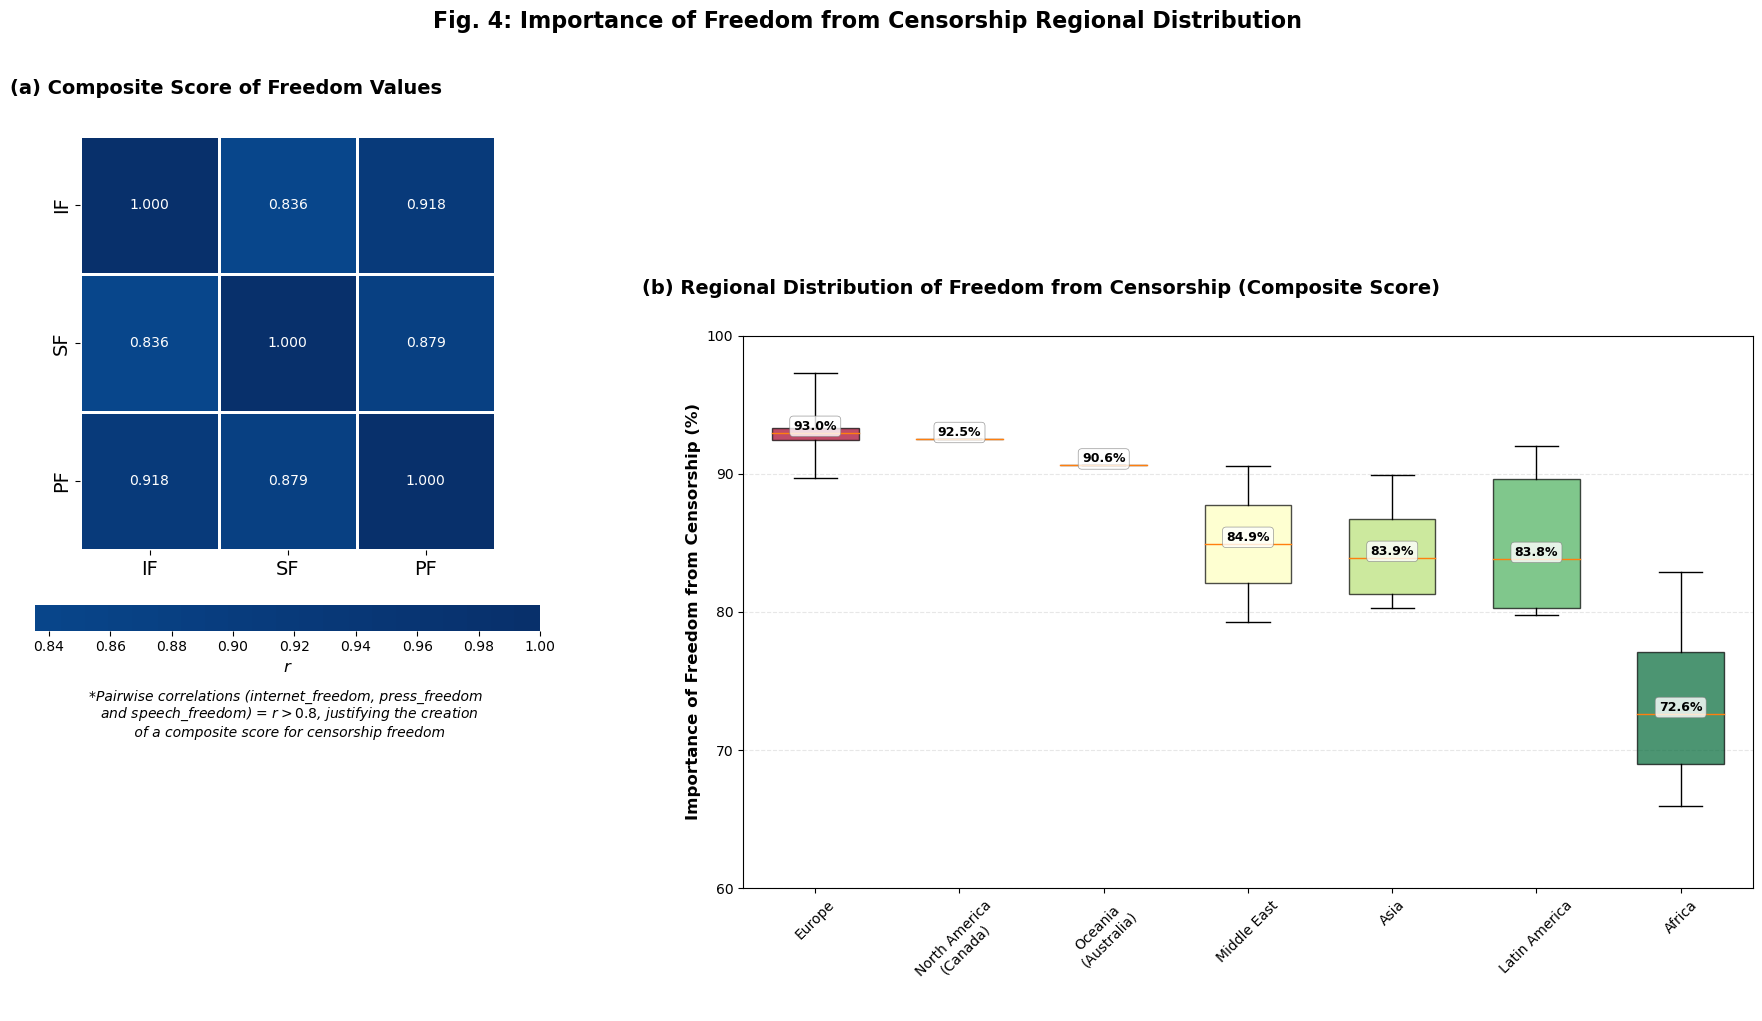

In [171]:
from scipy.stats import spearmanr
from matplotlib.colors import LinearSegmentedColormap

# ===== PART A: Correlation Matrix =====

# Calculate freedom importance for each country
def calc_freedom_importance(freedom_var):
    valid_data = pew[
        pew[freedom_var].isin(['1', '2', '3', '4'])
    ].copy()
    valid_data['weight'] = pd.to_numeric(valid_data['weight'], errors='coerce')
    valid_data = valid_data.dropna(subset=['weight', 'country_name', freedom_var])
    
    country_stats = {}
    for country in sorted(valid_data['country_name'].unique()):
        country_data = valid_data[valid_data['country_name'] == country]
        total_weight = country_data['weight'].sum()
        
        freedom_important = country_data[country_data[freedom_var].isin(['1', '2'])]['weight'].sum()
        freedom_important_pct = (freedom_important / total_weight) * 100
        
        country_stats[country] = freedom_important_pct
    
    return pd.Series(country_stats)

# Calculate for all three
internet_scores = calc_freedom_importance('internet_freedom')
speech_scores = calc_freedom_importance('free_speech')
press_scores = calc_freedom_importance('press_freedom')

# Align all three series to same countries
common_countries = internet_scores.index.intersection(speech_scores.index).intersection(press_scores.index)
internet_aligned = internet_scores[common_countries]
speech_aligned = speech_scores[common_countries]
press_aligned = press_scores[common_countries]

# Create correlation matrix
corr_matrix = pd.DataFrame({
    'Internet Freedom': internet_aligned,
    'Free Speech': speech_aligned,
    'Press Freedom': press_aligned
}).corr(method='spearman')

# ===== PART B: Boxplot by Region =====

# Define region mapping
region_map = {
    'UK': 'Europe', 'France': 'Europe', 'Germany': 'Europe', 'Italy': 'Europe',
    'Spain': 'Europe', 'Netherlands': 'Europe', 'Sweden': 'Europe', 'Greece': 'Europe',
    'Poland': 'Europe', 'Hungary': 'Europe',
    'Canada': 'North America (Canada)',
    'Japan': 'Asia', 'South Korea': 'Asia', 'India': 'Asia', 'Indonesia': 'Asia',
    'Malaysia': 'Asia', 'Philippines': 'Asia', 'Singapore': 'Asia', 'Thailand': 'Asia',
    'Bangladesh': 'Asia', 'Sri Lanka': 'Asia',
    'Israel': 'Middle East', 'Turkey': 'Middle East', 'Tunisia': 'Middle East',
    'Ghana': 'Africa', 'Kenya': 'Africa', 'Nigeria': 'Africa', 'South Africa': 'Africa',
    'Argentina': 'Latin America', 'Brazil': 'Latin America', 'Chile': 'Latin America',
    'Colombia': 'Latin America', 'Mexico': 'Latin America', 'Peru': 'Latin America',
    'Australia': 'Oceania (Australia)'
}

# Create composite score
composite_scores = (internet_aligned + speech_aligned + press_aligned) / 3

# Create DataFrame with composite scores and regions
composite_df = pd.DataFrame({
    'Country': composite_scores.index,
    'Composite_Freedom_Score': composite_scores.values,
    'Region': [region_map.get(country, 'Other') for country in composite_scores.index]
})

# Define region order
region_order = ['Europe', 'North America (Canada)', 'Oceania (Australia)', 'Middle East', 'Asia', 'Latin America', 'Africa']

# Prepare data for boxplot
box_data = []
box_labels = []

for region in region_order:
    region_data = composite_df[composite_df['Region'] == region]['Composite_Freedom_Score'].values
    if len(region_data) > 0:
        box_data.append(region_data)
        # Replace " (text)" with "\n(text)" to put bracketed text on new line
        label = region.replace(' (', '\n(')
        box_labels.append(label)

# ===== CREATE COMBINED FIGURE =====

fig, axes = plt.subplots(1, 2, figsize=(20, 8))

# ===== SUBPLOT A: Correlation Matrix =====
ax_a = axes[0]

# Rename columns/rows for shorthand
corr_matrix_renamed = corr_matrix.copy()
corr_matrix_renamed.columns = ['IF', 'SF', 'PF']
corr_matrix_renamed.index = ['IF', 'SF', 'PF']

sns.heatmap(corr_matrix_renamed, annot=True, fmt='.3f', cmap='Blues', center=0,
            square=True, linewidths=1, 
            cbar_kws={"shrink": 0.5, "orientation": "horizontal", "pad": 0.1}, 
            ax=ax_a, 
            xticklabels=True, yticklabels=True)  # Keep default labels

# Make colorbar label bold
cbar = ax_a.collections[0].colorbar
cbar.set_label('$r$', fontsize=12)  # Increase from default (usually 10-12)
cbar.ax.xaxis.label.set_fontsize(12)

# Make tick labels bigger
ax_a.tick_params(axis='both', labelsize=14)  # Increase from default (usually 10-12)

ax_a.set_title('(a) Composite Score of Freedom Values', fontsize=14, fontweight='bold', pad=30, loc='left', x=-0.17)

# Add explanatory text below the heatmap
ax_a.text(0.5, -0.45, '*Pairwise correlations (internet_freedom, press_freedom \n and speech_freedom) = $r > 0.8$, justifying the creation \n of a composite score for censorship freedom',
          transform=ax_a.transAxes, fontsize=10, ha='center', 
          style='italic', color='black')

# ===== SUBPLOT B: Boxplot by Region =====
ax_b = axes[1]

# Use RdYlGn colormap (red-yellow-green)
cmap_gradient = plt.cm.RdYlGn

# Create boxplot
bp = ax_b.boxplot(box_data, labels=box_labels, patch_artist=True,
                  widths=0.6, showmeans=False, meanline=False, whis=10.0)

# Color boxes with gradient
# Color boxes with gradient
for i, patch in enumerate(bp['boxes']):
    # Normalize position: 0 = first region (Europe), 1 = last region (Africa)
    color_value = i / (len(bp['boxes']) - 1) if len(bp['boxes']) > 1 else 0
    color = cmap_gradient(color_value)
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

# Add median labels
for i, (data, label) in enumerate(zip(box_data, box_labels)):
    median_val = np.median(data)
    x_pos = i + 1  # Boxplot positions start at 1
    ax_b.text(x_pos, median_val, f'{median_val:.1f}%', 
              ha='center', va='bottom', fontsize=9, fontweight='bold',
              bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.8, edgecolor='gray', linewidth=0.5))

# Customize subplot B
ax_b.set_ylabel('Importance of Freedom from Censorship (%)', fontsize=12, fontweight='bold')

# Customize subplot B
ax_b.set_ylabel('Importance of Freedom from Censorship (%)', fontsize=12, fontweight='bold')
ax_b.set_xlabel(' ', fontsize=12, fontweight='bold')
ax_b.set_title('(b) Regional Distribution of Freedom from Censorship (Composite Score)', 
               fontsize=14, fontweight='bold', pad=30, loc='left', x=-0.10)
ax_b.tick_params(axis='x', rotation=45)
ax_b.grid(True, alpha=0.3, axis='y', linestyle='--')
ax_b.set_ylim(60, 100)
ax_b.set_yticks(np.arange(60, 101, 10)) 

# Overall figure title
fig.suptitle('Fig. 4: Importance of Freedom from Censorship Regional Distribution', 
            fontsize=16, fontweight='bold', x=0.55, y=1.02)

plt.tight_layout()

# Adjust position - move ax_b lower
ax_b_pos = ax_b.get_position()
ax_b.set_position([ax_b_pos.x0, ax_b_pos.y0 - 0.25, ax_b_pos.width, ax_b_pos.height])

# Statistical test: Kruskal-Wallis test
from scipy.stats import kruskal

# Run Kruskal-Wallis test on all region groups
if len(box_data) > 2:
    h_stat, p_val = kruskal(*box_data)
    
#    print(f"\nH-statistic: {h_stat:.3f}")
#    print(f"p-value: {p_val:.4f}")

plt.show()



Given that the Pew survey grouped internet freedom, free speech, and press freedom under 'censorship', measuring the same underlying construct (importance of freedom from state censorship), a composite score $C_c$ was created for each country $c$ by averaging the three variables: $C_c = \frac{1}{3}(I_c + S_c + P_c)$, where $I_c$, $S_c$, and $P_c$ represent the weighted proportions for internet freedom, speech freedom, and press freedom respectively. Spearman's correlation coefficient $ρ$ was calculated to verify pairwise relationships between variables (Figure 4a), with all correlations $r > 0.8$, justifying the composite score. This composite score was then used to map regional distributions. Boxplot (b) revealed that freedom from censorship was deemed more important in Western regions, with medians $M$ diminishing across regions: Europe ($M = 93\%$), Middle East ($M = 84.9\%$), Asia ($M = 83.9\%$), Latin America ($M = 83.8\%$), and Africa ($M = 72.6\%$). Kruskal-Wallis tests were applied to verify observed differences between regional groups, revealing test statistic $H = 22.674$ and $p = 0.0009$, indicating statistically significant differences in freedom importance across regions.

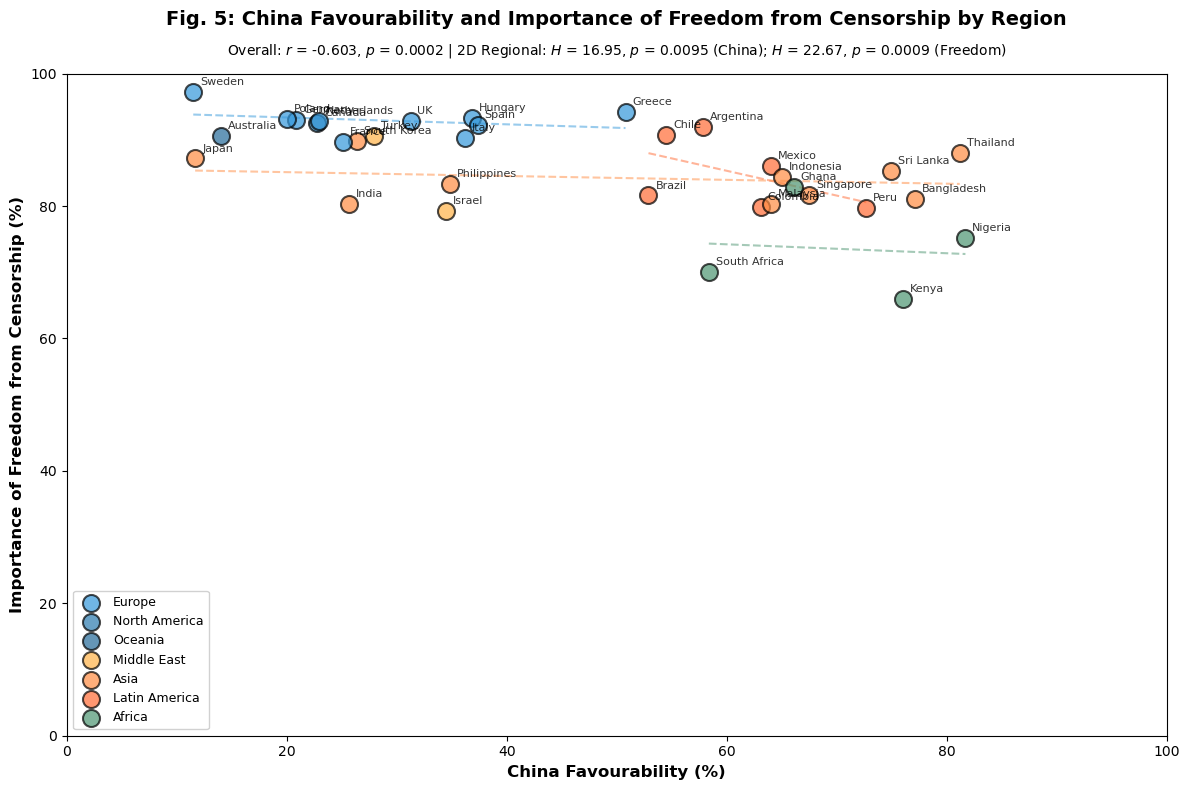

In [242]:
# Figure 5: China Favourability vs. Freedom from Censorship (Composite Score) by Region

# Calculate China favourability for each country
valid_data_china = pew[pew['fav_china'].isin(['1', '2', '3', '4'])].copy()
valid_data_china['weight'] = pd.to_numeric(valid_data_china['weight'], errors='coerce')
valid_data_china = valid_data_china.dropna(subset=['weight', 'country_name', 'fav_china'])

china_favourability = {}
for country in sorted(valid_data_china['country_name'].unique()):
    country_data = valid_data_china[valid_data_china['country_name'] == country]
    total_weight = country_data['weight'].sum()
    
    fav_china_favorable = country_data[country_data['fav_china'].isin(['1', '2'])]['weight'].sum()
    fav_china_favorable_pct = (fav_china_favorable / total_weight) * 100
    
    china_favourability[country] = fav_china_favorable_pct

# Get composite freedom scores
def calc_freedom_importance(freedom_var):
    valid_data = pew[
        pew[freedom_var].isin(['1', '2', '3', '4'])
    ].copy()
    valid_data['weight'] = pd.to_numeric(valid_data['weight'], errors='coerce')
    valid_data = valid_data.dropna(subset=['weight', 'country_name', freedom_var])
    
    country_stats = {}
    for country in sorted(valid_data['country_name'].unique()):
        country_data = valid_data[valid_data['country_name'] == country]
        total_weight = country_data['weight'].sum()
        
        freedom_important = country_data[country_data[freedom_var].isin(['1', '2'])]['weight'].sum()
        freedom_important_pct = (freedom_important / total_weight) * 100
        
        country_stats[country] = freedom_important_pct
    
    return pd.Series(country_stats)

internet_scores = calc_freedom_importance('internet_freedom')
speech_scores = calc_freedom_importance('free_speech')
press_scores = calc_freedom_importance('press_freedom')

common_countries = internet_scores.index.intersection(speech_scores.index).intersection(press_scores.index)
internet_aligned = internet_scores[common_countries]
speech_aligned = speech_scores[common_countries]
press_aligned = press_scores[common_countries]

composite_scores = (internet_aligned + speech_aligned + press_aligned) / 3

# Create DataFrame combining China favourability and composite freedom scores
plot_df = pd.DataFrame({
    'Country': composite_scores.index,
    'China_Favourability': [china_favourability.get(country, np.nan) for country in composite_scores.index],
    'Composite_Freedom_Score': composite_scores.values,
    'Region': [region_map.get(country, 'Other') for country in composite_scores.index]
})

# Remove any rows with missing data
plot_df = plot_df.dropna()

# Define region colors
region_colors = {
    'Europe': '#3498db',  # Darker reddish
    'North America (Canada)': '#2a7aaf',  # Similar to original Europe color
    'Oceania (Australia)': '#246a99',  # Similar to original Europe, slightly lighter
    'Middle East': '#ffb347',  # Light orange
    'Asia': '#ff8c42',  # Medium orange
    'Latin America': '#ff6b35',  # Darker orange-red
    'Africa': '#4c9571'
}

# Legend label mapping (to simplify region names)
legend_labels = {
    'North America (Canada)': 'North America',
    'Oceania (Australia)': 'Oceania'
}

# STATISTICAL ANALYSIS
from scipy.stats import spearmanr
import numpy as np

# Overall correlation
corr_overall, p_val_overall = spearmanr(plot_df['China_Favourability'], plot_df['Composite_Freedom_Score'])

# REGIONAL POSITIONING/CLUSTERING 
from scipy.stats import kruskal

# Test if regions differ in their positions using Kruskal-Wallis
region_groups_china = []
region_groups_freedom = []
region_names = []

for region in sorted(plot_df['Region'].unique()):
    region_data = plot_df[plot_df['Region'] == region]
    if len(region_data) > 0:  # Only exclude if completely empty
        region_groups_china.append(region_data['China_Favourability'].values)
        region_groups_freedom.append(region_data['Composite_Freedom_Score'].values)
        region_names.append(region)

# Run Kruskal-Wallis tests (need at least 2 groups)
if len(region_groups_china) > 1:
    h_china, p_china = kruskal(*region_groups_china)
    h_freedom, p_freedom = kruskal(*region_groups_freedom)
else:
    h_china, p_china, h_freedom, p_freedom = None, None, None, None

# Run Kruskal-Wallis tests (need at least 2 groups)
if len(region_groups_china) > 1:
    h_china, p_china = kruskal(*region_groups_china)
    h_freedom, p_freedom = kruskal(*region_groups_freedom)

# ===== VISUALIZATION =====
fig, ax = plt.subplots(figsize=(12, 8))

# Plot each region with different colors and separate trend lines
for region in plot_df['Region'].unique():
    region_data = plot_df[plot_df['Region'] == region]
    color = region_colors.get(region, 'gray')
    
    # Get legend label (use simplified name if available, otherwise use original)
    legend_label = legend_labels.get(region, region)
    
    # Scatter plot
    ax.scatter(region_data['China_Favourability'], region_data['Composite_Freedom_Score'],
              s=150, alpha=0.7, edgecolors='black', linewidth=1.5,
              label=legend_label, color=color, zorder=3)
    
    # Separate trend line for this region (if enough points)
    if len(region_data) >= 3:
        z = np.polyfit(region_data['China_Favourability'], 
                      region_data['Composite_Freedom_Score'], 1)
        p = np.poly1d(z)
        x_sorted = np.sort(region_data['China_Favourability'])
        ax.plot(x_sorted, p(x_sorted), 
                color=color, linestyle='--', alpha=0.5, linewidth=1.5, zorder=1)

# Add country labels
for idx, row in plot_df.iterrows():
    ax.annotate(row['Country'], 
               (row['China_Favourability'], row['Composite_Freedom_Score']),
               fontsize=8, alpha=0.8, xytext=(5, 5), textcoords='offset points')

# Customize
ax.set_xlabel('China Favourability (%)', fontsize=12, fontweight='bold')
ax.set_ylabel('Importance of Freedom from Censorship (%)', fontsize=12, fontweight='bold')

# Create comprehensive title with all three statistics
title_line1 = f'Fig. 5: China Favourability and Importance of Freedom from Censorship by Region'
title_line2 = f'Overall: $r$ = {corr_overall:.3f}, $p$ = {p_val_overall:.4f} | 2D Regional: $H$ = {h_china:.2f}, $p$ = {p_china:.4f} (China); $H$ = {h_freedom:.2f}, $p$ = {p_freedom:.4f} (Freedom)'

# Set main title (larger font, more padding to create gap)
ax.set_title(title_line1, fontsize=14, fontweight='bold', pad=35)

# Add smaller statistics line below with gap (lower y value = more gap from title)
ax.text(0.5, 1.02, title_line2, transform=ax.transAxes, 
        fontsize=10, ha='center', va='bottom')

ax.set_xlim(0, 100)
ax.set_ylim(0, 100)

# After all the plotting code, before plt.show():

# Get current handles and labels
handles, labels = ax.get_legend_handles_labels()

# Define the desired order
desired_order = [
    'Europe',
    'North America',
    'Oceania',
    'Middle East',
    'Asia',
    'Latin America',
    'Africa'
]

# Create ordered handles and labels
ordered_handles = []
ordered_labels = []
for desired_label in desired_order:
    if desired_label in labels:
        idx = labels.index(desired_label)
        ordered_handles.append(handles[idx])
        ordered_labels.append(desired_label)

# Set the legend with ordered handles and labels
ax.legend(ordered_handles, ordered_labels, loc='lower left', framealpha=0.9, fontsize=9, ncol=1)

plt.tight_layout()
plt.show()

Fig. 5 tests whether the relationship between China favourability and freedom importance from censorship is correlated by geographic region. While the overall correlation was $r = -0.603$ ($p < 0.002$), *within*-region analyses revealed no significant correlations (all $p > 0.05$), indicating that China favourability and freedom importance does not correlate uniformly within individual regions. However, Kruskal-Wallis tests demonstrated that regions do cluster distinctly in 2D space and differ significantly in their positions: China favourability ($H = 13.232$, $p = 0.0042$) freedom from censorship ($H = 20.204$, $p = 0.0002$). Europe clusters around high freedom importance and low China favourability, while Africa shows the inverse pattern. The overall negative correlation exists because positional patterns do present between distinct regions, although not within them.

In [240]:
# In Figure 4, check what's being tested:
print("Figure 4 Kruskal-Wallis:")
print(f"Number of region groups: {len(box_data)}")
for i, (data, label) in enumerate(zip(box_data, box_labels)):
    print(f"  {label}: n={len(data)}, values={data}")

# In Figure 5, check what's being tested:
print("\nFigure 5 Kruskal-Wallis (Freedom):")
print(f"Number of region groups: {len(region_groups_freedom)}")
for i, group in enumerate(region_groups_freedom):
    region_name = [r for r in plot_df['Region'].unique() if len(plot_df[plot_df['Region'] == r]) == len(group)][0]
    print(f"  {region_name}: n={len(group)}, values={group}")

Figure 4 Kruskal-Wallis:
Number of region groups: 7
  Europe: n=10, values=[89.68339833 93.06894708 94.14569962 93.32208928 90.32938511 92.78589487
 93.16254709 92.29300962 97.29696246 92.86520489]
  North America
(Canada): n=1, values=[92.52058172]
  Oceania
(Australia): n=1, values=[90.60431111]
  Middle East: n=2, values=[79.30117402 90.5625945 ]
  Asia: n=10, values=[81.1159587  80.2498196  84.45100588 87.18271877 80.31475757 83.37764874
 81.71217685 89.88401872 85.29081513 88.0519782 ]
  Latin America: n=6, values=[91.98554099 81.59763209 90.75671244 79.8581405  86.0847467  79.76587187]
  Africa: n=4, values=[82.87403006 65.92779696 75.21796401 70.00829283]

Figure 5 Kruskal-Wallis (Freedom):
Number of region groups: 4
  Latin America: n=6, values=[91.98554099 81.59763209 90.75671244 79.8581405  86.0847467  79.76587187]
  Asia: n=10, values=[81.1159587  80.2498196  84.45100588 87.18271877 80.31475757 83.37764874
 81.71217685 89.88401872 85.29081513 88.0519782 ]
  Asia: n=10, value

In [239]:
# Compare composite scores between Figure 4 and Figure 5
print("Comparing composite scores...\n")

# Get composite scores from Figure 4 (after it's created)
fig4_scores = composite_df.set_index('Country')['Composite_Freedom_Score']

# Get composite scores from Figure 5 (after plot_df is created)
fig5_scores = plot_df.set_index('Country')['Composite_Freedom_Score']

# Check if they're identical
if fig4_scores.equals(fig5_scores):
    print("✓ Composite scores are identical")
else:
    print("✗ Composite scores differ!")
    print("\nDifferences:")
    diff = fig4_scores - fig5_scores
    print(diff[diff != 0])
    
    # Check if it's just floating point precision
    if (fig4_scores - fig5_scores).abs().max() < 0.01:
        print("\n(But differences are < 0.01%, likely just floating point precision)")

# Check region assignments
print("\n\nComparing region assignments...\n")
fig4_regions = composite_df.set_index('Country')['Region']
fig5_regions = plot_df.set_index('Country')['Region']

if fig4_regions.equals(fig5_regions):
    print("✓ Region assignments are identical")
else:
    print("✗ Region assignments differ!")
    diff_regions = fig4_regions != fig5_regions
    print(fig4_regions[diff_regions])
    print(fig5_regions[diff_regions])

Comparing composite scores...

✓ Composite scores are identical


Comparing region assignments...

✓ Region assignments are identical


# Discussion 

Link to the relevant literature and angle of your essay

Whilst global majority countries favour China more, this does not necessarily mean that they hold the Americas and West up to a lower standard. Favourable outlooks of the West are still on average much higher than China, implying _X_ about values. This extends to freedom values.... blah blah blah 



re figure 3: Despite significant structural differences between the United States and the European Union, both were perceived with a degree of favourability along these same lines. Taken with the previous figures, this implies that a global favourability towards Western institutions further adds to the argument that freedom is valued with underlying differences.

This pattern—where Western powers (US/EU) are perceived similarly while China follows a distinct distribution—combined with the correlation analysis showing China favorability is inversely related to freedom values (Figure 2) and the geographic patterns showing Global Majority vs non-Global Majority differences (Figure 1), suggests that perceptions of China reflect underlying differences in how countries value freedom and governance, supporting the theoretical framework that cross-national attitudes toward China function as a lens onto value commitments and reveal patterns of positionality and power relations between nations.

The EU was most favoured across the 35 countries, closely followed by the US. China showed much less favorability. Combined with Fig 2 showing that China favorability is inversely related to the importance placed on freedom from censorship, this distinct distribution pattern suggests that how countries perceive China may reflect underlying differences in how they value freedom and governance.

Results imply that perceptions of China follow systematically different patterns compared to perceptions of Western powers (US and EU). 

Further analysis would have compared perceived vs importance of freedoms, and may have also looked at democracy

Limitations:

Certain groups, i.e. middle east is limited and so forth.